# ToolNode 실습: 자료실 문의 그래프에 오류 처리 함수와 실행 한도 붙이기

**이 노트북에서 할 일**

1. 01절 그래프에 02절 오류 처리 함수와 03절 실행 한도를 붙여, 자료실 문의 하나를 처리합니다.
2. 도구 메시지의 결과 상태로 오류 처리 함수가 쓰였는지 보고, 그 흐름의 노드 실행 수를 셉니다.
3. 실행 한도 하나만 노드 실행 수와 같게 줄여 다시 실행하고, 두 실행을 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 실행 1의 모델 요청은 2번입니다.
실행 2는 한도에 닿아 결과를 받지 못해, 노트북 안에서는 그 요청 수를 셀 수 없습니다.
노트북 밖에서 같은 흐름을 다섯 번 보냈을 때 실행 2도 2번이어서, 모두 4번으로 어림합니다.

모델이 도구를 몇 번 부르느냐에 따라 요청 수는 달라질 수 있습니다.
요금표로 어림한 예상 비용은 0.01달러 아래이고, 청구 금액이 아닙니다.
도구는 노트북 안 규정 딕셔너리를 읽기만 하고, 읽는 파일과 새로 쓰는 파일은 없습니다.

앞에서 배운 함수 넷은 도구 파일 `graph_tools.py`에서 가져옵니다.
걸린 시간은 재지 않습니다. 교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 langgraph 1.2.11, langchain 1.4.0, langchain-core 1.6.2입니다.
langchain-openai 1.6.0과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~04절에서 쓴 이름과 문법만 씁니다.

실습 폴더 `labs/part5/ch20-tool-node`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위에 초록 상자 둘이 나란히 있습니다. 왼쪽은 첫 상태 대출 문의 하나, 오른쪽은 설정 딕셔너리 03절 recursion_limit 10입니다. 두 상자에서 invoke 첫째 인자와 둘째 인자 화살표가 아래 01절 그래프 모양 칸으로 갑니다. 칸 안에서 회색 가상 시작점 START가 보라 상자 모델 노드 model로 가고, 모델 노드에서 점선 두 갈래가 나갑니다. 요청 있음 이름표 tools 갈래는 회색 상자 도구 실행 노드 tools ToolNode로, 요청 없음 명시적 종료 갈래는 회색 가상 끝점 END로 갑니다. 도구 실행 노드에서 되돌아가는 엣지 실선이 모델 노드로 오고, 도구 실행 노드와 선으로 이은, 양옆에 세로줄이 한 줄씩 더 있는 파란 상자 오류 처리 함수 02절 handle_policy_error 이번 흐름에서 쓰이지 않음이 있는 그림](attachment:05-1-오류-처리-함수와-한도를-붙인-그래프.png)

위에서 아래로 읽습니다. 아래 칸에서 오류 처리 함수를 뺀 상자 넷과 화살표 넷은 노트북 5절 구조 문자열과 같습니다.
보라 상자는 모델에 요청을 보내는 모델 노드이고, 회색은 LangGraph가 준 것입니다.
오류 처리 함수는 노드가 아니라서 양옆에 세로줄이 더 있는 파란 상자로 그렸고, 이번 두 실행에서는 쓰이지 않았습니다.
맨 위 초록 상자 둘은 메서드 `invoke`에 넘기는 두 인자이고, 실행 2에서는 오른쪽 한도만 바꿉니다.
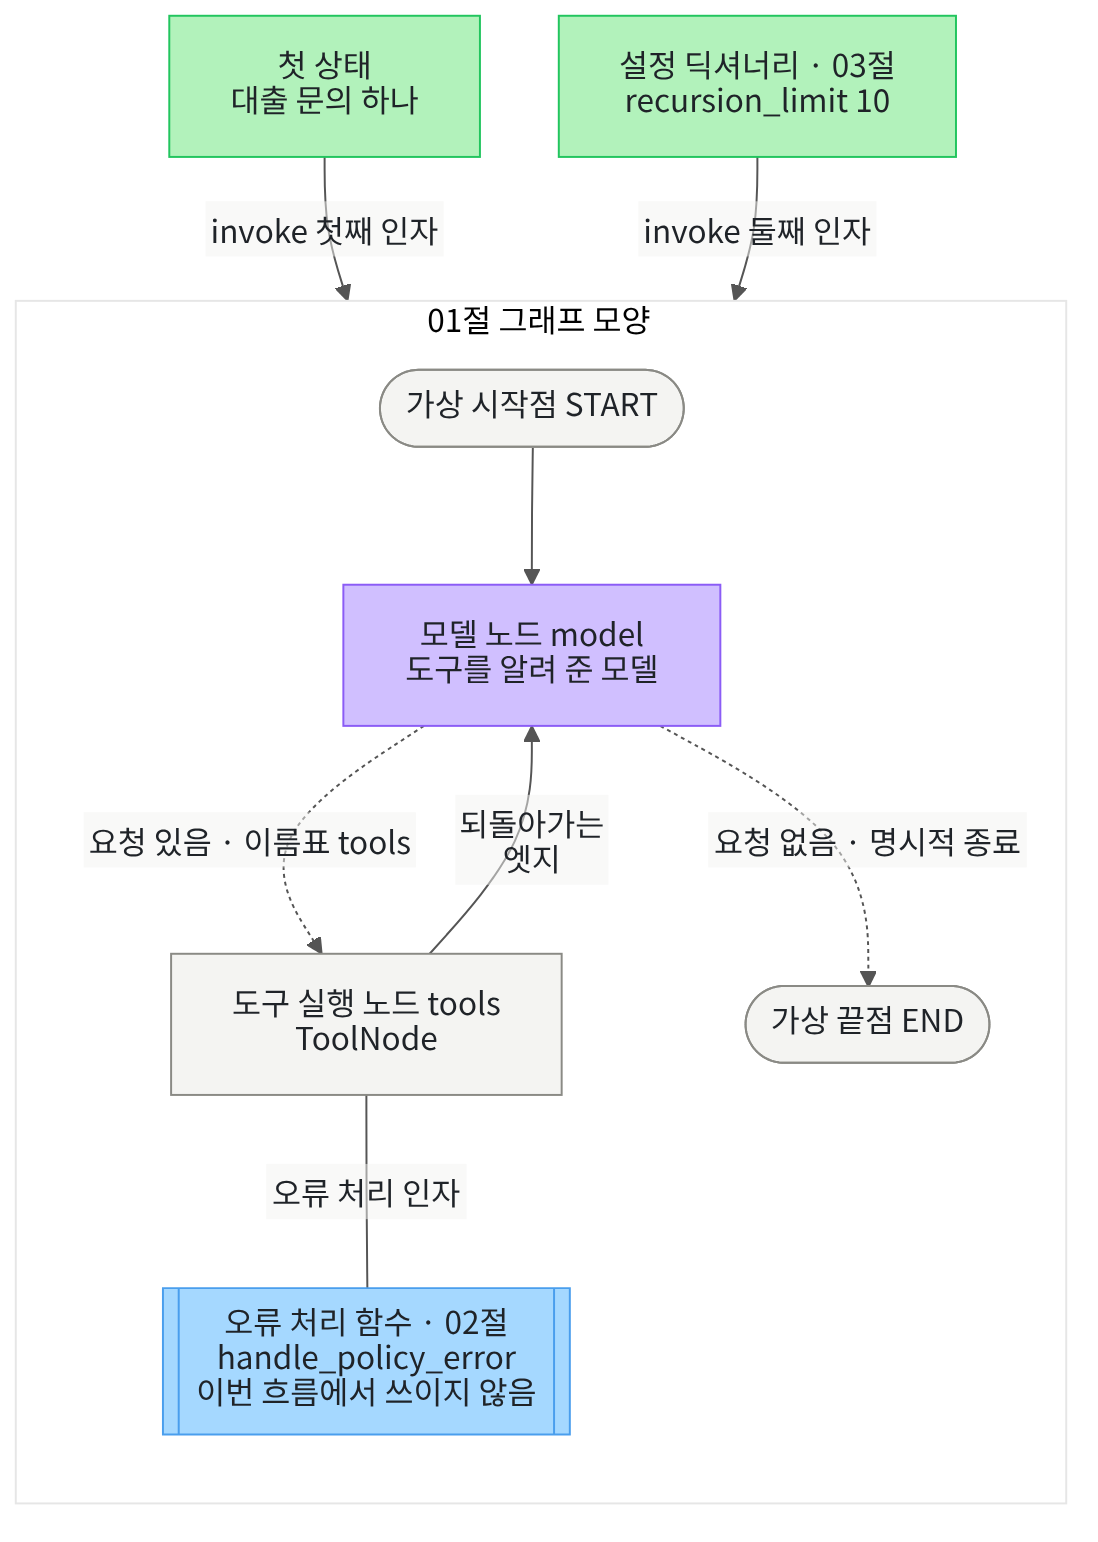

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01절 그래프에 02절 오류 처리 함수와 03절 실행 한도를 붙여, 자료실 문의 하나를 처리합니다.
첫 셀은 패키지 다섯 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langgraph: 1.2.11
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`·`langchain: 1.4.0`·`langchain-core: 1.6.2`가 보입니다.
출력 줄 `langchain-openai: 1.6.0`과 `python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
그래프와 메시지 이름은 01절과 같고, 03절에서 본 오류 이름 `GraphRecursionError`를 더합니다.
도구 파일에서는 함수 넷을 가져옵니다.

In [2]:
# 01절 그래프 이름에 03절 오류 이름 하나를 더하고, 도구 파일의 함수 넷을 가져옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict

from langchain.chat_models import init_chat_model
from langchain.messages import AnyMessage, HumanMessage
from langchain.tools import tool
from langgraph.errors import GraphRecursionError
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from graph_tools import estimate_cost, run_row, show_messages, sum_usage

print("이 절에서 도구 파일에 더한 함수:", "call_id_lists", "run_row")

이 절에서 도구 파일에 더한 함수: call_id_lists run_row


**결과 읽기** — 출력 줄 `이 절에서 도구 파일에 더한 함수: call_id_lists run_row`가 보입니다.

앞에서 배운 함수는 `graph_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

이 절에서 도구 파일에 01절 함수 둘을 더했습니다.
함수 `run_row`는 실행 결과 하나를 기록 한 줄로 만들고, 안에서 함수 `call_id_lists`를 부릅니다.
두 함수 모두 01절 노트북의 본문을 글자 그대로 옮겼습니다.
함수 `show_messages`는 Ch 19 06절, `sum_usage`는 Ch 19 05절, `estimate_cost`는 Ch 6 06절에서 배웠습니다.

## 2. 키와 모델 준비

모델은 01절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 도구 호출 요청을 보낼지가 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-24에 이 모델로 실행한 결과입니다.

## 3. 오늘 처리할 문의

이번 실습은 자료실 창구에 들어온 문의 하나를 그래프로 처리합니다.
문의 글은 01절 7절 대출 질문 그대로이고, 이 절에서 실행 전에 정했습니다.
다음 셀은 문의 글로 첫 상태를 만듭니다.
이 첫 상태를 실행 1과 실행 2에 똑같이 넣습니다.

In [5]:
# 오늘 처리할 자료실 문의 하나로 첫 상태를 만듭니다(01절 7절 대출 질문과 같은 글)
inquiry = "자료실에서 일반 도서를 며칠 빌릴 수 있나요?"
inquiry_state = {"messages": [HumanMessage(content=inquiry)], "trace": []}
print("문의:", inquiry)
print("출처: 01절 7절 대출 질문 그대로, 이 절에서 실행 전에 정함")
state_keys = list(inquiry_state.keys())
print("첫 상태의 칸:", state_keys)

문의: 자료실에서 일반 도서를 며칠 빌릴 수 있나요?
출처: 01절 7절 대출 질문 그대로, 이 절에서 실행 전에 정함
첫 상태의 칸: ['messages', 'trace']


**결과 읽기** — 출력 줄 `첫 상태의 칸: ['messages', 'trace']`로 메시지 칸과 실행 흔적 칸을 확인합니다.
메시지 칸에는 문의 하나를 담고, 흔적 칸은 빈 목록으로 두었습니다.
출력 줄 `출처:`는 이 문의가 어디서 왔는지 적은 줄입니다.

## 4. 재료 · 자료와 도구와 오류 처리 함수

다음 셀은 01절과 글자까지 같은 셀로, 주제어를 키로 한 규정 딕셔너리를 만듭니다.

In [6]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
오늘 문의는 대출 규정을 찾아야 답할 수 있는 질문입니다.

다음 셀은 03·04절과 글자까지 같은 도구 셀입니다.
01절 도구와 코드가 같고, 오류 줄 위 주석 한 줄만 「02절에서 본 ValueError」로 적었습니다.

In [7]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(02절에서 본 ValueError입니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
딕셔너리에 없는 주제어를 받으면, 도구는 `ValueError`를 냅니다.

다음 셀은 01절과 글자까지 같은 셀로, 도구 목록을 모델에게 알려 준 `bound_model`을 만듭니다.

In [8]:
# 도구 목록을 모델에게 알려 줍니다(Ch 19 04절 bind_tools, 요청은 아직 보내지 않음)
tools = [lookup_policy]
# 한 응답에 도구 호출 요청을 하나까지만 받게 합니다(Ch 19 06절과 같은 값)
bound_model = model.bind_tools(tools, parallel_tool_calls=False)
print("실어 보낼 명세 수:", len(bound_model.kwargs["tools"]))
print("여럿 담기:", bound_model.kwargs["parallel_tool_calls"])

실어 보낼 명세 수: 1
여럿 담기: False


**결과 읽기** — 출력 줄 `실어 보낼 명세 수: 1`과 `여럿 담기: False`는 01절과 같습니다.
한 응답에는 도구 호출 요청이 하나까지만 담깁니다.
그래서 요청이 든 응답마다 도구 실행 노드가 한 번 실행되고, 도구 메시지가 하나 생깁니다.

다음 셀은 02절 7절과 글자까지 같은 오류 처리 함수입니다.
도구 실행 노드가 넘긴 `ValueError` 하나로, 도구 메시지에 담을 안내 글을 만들어 내놓습니다.
첫 매개변수 뒤 `: ValueError`는 02절에서 본 받을 오류 표시이고, 라이브러리가 이 표시를 읽습니다.

In [9]:
# 도구 실행 노드가 넘긴 ValueError 하나로, 도구 메시지에 담을 안내 글을 만들어 내놓습니다
def handle_policy_error(error: ValueError):
    # 첫 매개변수의 표시 ValueError를 도구 실행 노드가 읽고, 이 종류의 오류만 이 함수에 넘깁니다
    reason = str(error)
    # 무엇이 잘못됐는지와, 이 도구로 찾을 수 있는 주제어를 함께 적습니다
    return "규정을 찾지 못했습니다(" + reason + "). 이 도구로 찾을 수 있는 주제어는 대출, 운영, 연체입니다."

**결과 읽기** — 정의 셀이라 출력이 없습니다.
02절에서 본 설치판 소스대로면, 받을 오류 표시가 `ValueError`인 이 함수에는 다른 종류의 오류가 넘어오지 않습니다.

다음 셀은 이 함수를 그래프 없이 한 번 불러, 어떤 글을 내놓는지 봅니다.
02절 7절 셀과 코드가 같고, 첫 줄 주석만 이 절에 맞게 적었습니다.

In [10]:
# 02절 7절처럼 ValueError 하나를 직접 만들어, 도구 실행 노드 없이 오류 처리 함수에 넣어 봅니다
sample_error = ValueError("지원하지 않는 주제: 주차")
guide_text = handle_policy_error(sample_error)
print("내놓은 글:", guide_text)

내놓은 글: 규정을 찾지 못했습니다(지원하지 않는 주제: 주차). 이 도구로 찾을 수 있는 주제어는 대출, 운영, 연체입니다.


**결과 읽기** — 라벨 `내놓은 글:` 뒤에 안내 글 한 줄이 보입니다.
괄호 안 `지원하지 않는 주제: 주차`가 오류의 글이고, 괄호 뒤 문장이 주제어 안내입니다.
조립한 그래프에서 도구가 이 오류를 내면, 이 글이 도구 메시지의 내용이 됩니다.

## 5. 조립 · 01절 그래프에 오류 처리 함수 붙이기

조립에 쓰는 상태 형식과 모델 노드는 01절 셀 그대로입니다.
다음 셀은 01절과 글자까지 같은 상태 형식입니다.

In [11]:
# 메시지 칸과 실행 흔적 칸에 각각 규칙을 적은 상태 형식을 만듭니다(Ch 13 04절 모양)
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메시지 칸에는 메시지 리듀서, 실행 흔적 칸에는 이어 붙이기 규칙을 적었습니다.

다음 셀은 01절과 글자까지 같은 모델 노드입니다.

In [12]:
# 메시지 칸 전체를 도구를 알려 준 모델에 보내고, 응답 하나와 노드 이름만 냅니다
def call_model(state):
    response = bound_model.invoke(state["messages"])
    return {"messages": [response], "trace": ["model"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드를 지날 때마다 모델 요청이 한 번 나가고, 실행 흔적 칸에 `model`이 붙습니다.

다음 셀은 02절 7절처럼 오류 처리 함수를 넘겨 도구 실행 노드를 만듭니다.
오류 처리 인자 `handle_tool_errors`에 4절의 함수를 넘깁니다.

In [13]:
# 02절 7절처럼 오류 처리 함수를 넘겨 도구 실행 노드를 만듭니다(아직 그래프에 넣지 않음)
policy_node = ToolNode(tools, handle_tool_errors=handle_policy_error)
print("만든 것의 종류:", type(policy_node).__name__)
# 속성 tools_by_name은 01절에서 본 도구 찾기 표입니다
table_keys = list(policy_node.tools_by_name.keys())
print("안에 든 도구 찾기 표의 키:", table_keys)

만든 것의 종류: ToolNode
안에 든 도구 찾기 표의 키: ['lookup_policy']


**결과 읽기** — 출력 줄 `만든 것의 종류: ToolNode`와 `안에 든 도구 찾기 표의 키: ['lookup_policy']`입니다.
01절 도구 실행 노드와 다른 것은 오류 처리 인자 하나입니다.

다음 셀은 01절과 글자까지 같은 이름표 표입니다.

In [14]:
# 도구 조건 함수의 이름표 둘을 실제로 갈 곳에 잇는 이름표 표를 만듭니다(Ch 13 03절)
path_map = {"tools": "tools", END: END}
print("이름표와 갈 곳을 이은 표:")
for label in path_map:
    print(label, "->", path_map[label])

이름표와 갈 곳을 이은 표:
tools -> tools
__end__ -> __end__


**결과 읽기** — 라벨 줄 아래 `tools -> tools`와 `__end__ -> __end__` 두 줄입니다.
도구 조건 함수가 `END`를 내놓으면 가상 끝점으로 갑니다.
03절에서 본 명시적 종료를, 이 그래프에서는 01절 도구 조건 함수가 맡습니다.

다음 셀은 01절 6절과 같은 노드와 엣지로 그래프를 조립합니다.
도구 실행 노드 자리에만 `policy_node`를 넣습니다.

In [15]:
# 01절 6절과 같은 노드와 엣지로 그래프를 조립합니다(도구 실행 노드 자리만 policy_node)
builder = StateGraph(AgentState)
builder.add_node("model", call_model)
builder.add_node("tools", policy_node)
builder.add_edge(START, "model")
builder.add_conditional_edges("model", tools_condition, path_map)
builder.add_edge("tools", "model")
graph = builder.compile()
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['model', 'tools']


**결과 읽기** — 출력 줄 `등록한 노드: ['model', 'tools']`입니다.
시작 엣지·조건부 엣지·되돌아가는 엣지는 01절과 같은 세 줄입니다.

다음 셀은 01절 6절과 글자까지 같은 셀로, 그래프가 스스로 그린 구조 문자열을 받아 옵니다.

In [16]:
# 컴파일한 그래프가 스스로 그린 구조 문자열을 받아 옵니다(Ch 13 01절)
structure_text = graph.get_graph().draw_mermaid()
print("그래프가 그린 구조:")
print(structure_text)

그래프가 그린 구조:
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools --> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**결과 읽기** — 라벨 줄 `그래프가 그린 구조:` 아래에서 화살표 줄 넷을 봅니다.
줄 `__start__ --> model`·`model -.-> __end__`·`model -.-> tools`·`tools --> model`입니다.
01절 6절 출력과 같은 넷이라, 오류 처리 함수를 넘겨도 그래프 모양은 그대로입니다.
오류 처리 함수는 노드가 아니라 도구 실행 노드 안에서 쓰여, 구조 문자열에 나오지 않습니다.

## 6. 실행 1 · 한도 10으로 문의 처리하기

첫 실행은 03절 4절과 같은 설정 딕셔너리로 합니다.
실행 한도는 그래프가 한 번 실행에서 진행할 수 있는 단계 수의 한도입니다.
실행 전에 예상해 봅니다.
01절 7절처럼 모델 노드·도구 실행 노드·모델 노드를 지나 끝나고, 모델 요청은 2번일 것입니다.
대출은 딕셔너리에 있는 주제어라, 오류 처리 함수는 쓰이지 않을 것입니다.

In [17]:
# 실행 1: 03절과 같은 설정 딕셔너리(한도 10)로 문의를 처리합니다(모델 요청 2번 예상)
limit_config = {"recursion_limit": 10}
print("설정 딕셔너리:", limit_config)
one_result = graph.invoke(inquiry_state, limit_config)
print("실행 흔적 칸:", one_result["trace"])
print("메시지 칸의 메시지 수:", len(one_result["messages"]))

설정 딕셔너리: {'recursion_limit': 10}


실행 흔적 칸: ['model', 'model']
메시지 칸의 메시지 수: 4


**결과 읽기** — 출력 줄 `설정 딕셔너리: {'recursion_limit': 10}`과 `실행 흔적 칸: ['model', 'model']`입니다.
출력 줄 `메시지 칸의 메시지 수: 4`입니다.
모델 노드를 두 번 지났으니, 모델 요청이 2번 나갔습니다.
한도 10에 닿지 않고, 메서드 `invoke`가 결과를 내놓았습니다.

다음 셀은 메시지 칸을 차례로 출력합니다.

In [18]:
# 메시지 칸을 차례로 출력합니다(Ch 19 06절 함수 show_messages)
print("메시지 칸:")
show_messages(one_result["messages"])

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래 네 줄이 메시지 칸입니다.
둘째 줄은 `AIMessage | 도구 호출 요청: ['lookup_policy']`, 넷째 줄은 `AIMessage | 도구 호출 요청: []`입니다.
셋째 줄 도구 메시지는 결과 상태 `success`에 대출 규정 글입니다.
도구가 오류를 내지 않아, 이번 흐름에서 오류 처리 함수는 쓰이지 않았습니다.

다음 셀은 첫 응답에 담긴 요청의 인자와, 도구 메시지의 결과 상태를 봅니다.

In [19]:
# 첫 응답의 도구 호출 요청 인자와, 셋째 메시지(도구 메시지)의 결과 상태를 봅니다
first_response = one_result["messages"][1]
for call in first_response.tool_calls:
    print("도구 이름:", call["name"], "| 인자:", call["args"])
tool_message = one_result["messages"][2]
print("셋째 메시지의 결과 상태:", tool_message.status)

도구 이름: lookup_policy | 인자: {'topic': '대출'}
셋째 메시지의 결과 상태: success


**결과 읽기** — 출력 줄 `도구 이름: lookup_policy | 인자: {'topic': '대출'}`입니다.
출력 줄 `셋째 메시지의 결과 상태: success`입니다.
모델이 딕셔너리에 있는 주제어 `대출`을 골라, 도구가 규정 글을 찾았습니다.
주제어는 모델이 정한 값이라, 실행한 때에 따라 달라질 수 있습니다.

다음 셀은 01절 10절 함수 `run_row`로 실행 결과를 기록 한 줄로 만들고, 노드 실행 수를 셉니다.
01절에서 본 것처럼 도구 실행 노드는 실행 흔적 칸을 쓰지 않습니다.
그래서 모델 노드를 지난 수, 곧 모델 요청 수에 도구 메시지 수를 더합니다.

In [20]:
# 실행 결과를 기록 한 줄로 만들고, 노드 실행 수를 셉니다(01절 10절 함수 run_row)
one_row = run_row("대출 문의", one_result)
print("기록 한 줄:", one_row)
# 도구 실행 노드는 흔적 칸을 쓰지 않으므로, 도구 메시지 수를 더해 노드 실행 수를 셉니다
one_steps = one_row["모델 요청 수"] + one_row["도구 메시지 수"]
print("노드 실행 수:", one_steps)

기록 한 줄: {'질문': '대출 문의', '실행 흔적': ['model', 'model'], '모델 요청 수': 2, '도구 메시지 수': 1, '호출 ID 짝': True}
노드 실행 수: 3


**결과 읽기** — 라벨 `기록 한 줄:` 뒤 딕셔너리에서 `'모델 요청 수': 2`와 `'도구 메시지 수': 1`을 봅니다.
칸 `'호출 ID 짝': True`로, 도구 메시지에 요청 id가 옮겨진 것도 확인합니다.
출력 줄 `노드 실행 수: 3`은 모델 노드 두 번과 도구 실행 노드 한 번입니다.
이 그래프는 단계마다 노드 하나를 실행하므로, 실행 1은 단계 셋을 지났습니다.

다음 셀은 마지막 응답을 봅니다.

In [21]:
# 마지막 응답의 도구 호출 요청 수와 답 글을 봅니다
last_message = one_result["messages"][-1]
print("마지막 응답의 도구 호출 요청 수:", len(last_message.tool_calls))
print("답 글:")
print(last_message.content)

마지막 응답의 도구 호출 요청 수: 0
답 글:
자료실의 일반 도서는 **1인 5권까지, 14일 동안** 빌릴 수 있습니다.


**결과 읽기** — 출력 줄 `마지막 응답의 도구 호출 요청 수: 0`입니다.
그래서 도구 조건 함수가 `END`를 내놓아 흐름이 끝났습니다.
03절 말로 명시적 종료이고, 실행 한도에 닿기 전에 일어났습니다.
라벨 줄 `답 글:` 아래는 모델이 도구 메시지를 읽고 쓴 답입니다.

이번 실행에서는 답 글이 도구 메시지의 1인 5권과 14일을 옮겨 적었습니다.
새 커널로 한 번 더 실행했을 때는 답 글의 쉼표 하나가 달랐습니다.
답 글은 실행마다 문장이 달라질 수 있어, 결론에 쓰지 않습니다.

## 7. 실행 2 · 바꿀 값은 실행 한도

바꿀 값은 실행 한도 하나입니다.
한도를 실행 1에서 센 노드 실행 수와 같게 줄이고, 첫 상태·그래프·모델 설정은 그대로 둡니다.
03절 6절에서는 노드를 세 번 실행하는 흐름이 한도 3에서 멈추고 한도 4에서 통과했습니다.
그때는 모델 없는 그래프였고, 이번에는 모델 요청이 든 흐름에서 그 경계의 멈추는 쪽을 봅니다.

다음 셀은 줄인 한도를 담은 설정 딕셔너리를 만듭니다.

In [22]:
# 바꿀 값: 실행 한도를 실행 1의 노드 실행 수와 같게 줄인 설정 딕셔너리를 만듭니다
tight_config = {"recursion_limit": one_steps}
print("실행 1의 설정 딕셔너리:", limit_config)
print("실행 2의 설정 딕셔너리:", tight_config)

실행 1의 설정 딕셔너리: {'recursion_limit': 10}
실행 2의 설정 딕셔너리: {'recursion_limit': 3}


**결과 읽기** — 출력 줄 `실행 2의 설정 딕셔너리: {'recursion_limit': 3}`입니다.
실행 1의 한도 10에서, 한도 하나만 3으로 바뀌었습니다.

다음 셀은 같은 첫 상태를 이 설정으로 실행합니다.
실행 전에 예상해 봅니다.
03절 규칙대로면 한도 3에서는 `GraphRecursionError`가 날 것입니다.
한도에 닿으면 오류가 올라오므로, 이 셀만 그 오류를 받아 출력합니다.

In [23]:
# 실행 2: 같은 첫 상태를 줄인 한도로 실행합니다(이 셀만 올라온 오류를 받아 출력합니다)
try:
    two_result = graph.invoke(inquiry_state, tight_config)
    print("끝까지 실행 | 실행 흔적 칸:", two_result["trace"])
except GraphRecursionError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:")
    print(error)

받은 오류: GraphRecursionError
오류 글:
Recursion limit of 3 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/GRAPH_RECURSION_LIMIT


**결과 읽기** — 출력 줄 `받은 오류: GraphRecursionError`입니다.
라벨 줄 `오류 글:` 아래 첫 줄은 `Recursion limit of 3 reached without hitting a stop condition.`로 시작합니다.
한도 3에 닿아, 메서드 `invoke`가 결과를 내놓지 않았습니다.
그래서 이 셀에서는 실행 흔적도, 답 글도, 사용량도 받지 못했습니다.
이 오류는 도구가 낸 오류가 아니라서, 오류 처리 함수가 받지 않았습니다.

노트북 밖에서 같은 흐름을 다섯 번 보냈을 때는, 실행 2도 모두 모델 노드를 두 번 지난 뒤 멈췄습니다.
둘째 요청은 답 글까지 만들었지만, 그 답은 받지 못했습니다.
노트북의 모델 노드는 01절 셀 그대로라, 부른 횟수를 따로 적지 않습니다.

## 8. 두 실행 견주기

다음 셀은 03절 6절 규칙으로, 실행 1의 흐름이 통과하는 가장 작은 한도를 셈합니다.
노드 실행 수보다 하나 큰 값입니다.
그 값을 두 실행의 한도와 견줍니다.

In [24]:
# 03절 6절 규칙(노드 실행 수보다 하나 큰 한도부터 통과)으로 통과 한도를 셈하고, 두 한도와 견줍니다
one_more = 1
pass_limit = one_steps + one_more
print("셈으로 통과하는 가장 작은 한도:", pass_limit)
print("실행 1 한도가 그 값보다 작은가:", limit_config["recursion_limit"] < pass_limit)
print("실행 2 한도가 그 값보다 작은가:", tight_config["recursion_limit"] < pass_limit)

셈으로 통과하는 가장 작은 한도: 4
실행 1 한도가 그 값보다 작은가: False
실행 2 한도가 그 값보다 작은가: True


**결과 읽기** — 출력 줄 `셈으로 통과하는 가장 작은 한도: 4`입니다.
출력 줄 `실행 1 한도가 그 값보다 작은가: False`와 `실행 2 한도가 그 값보다 작은가: True`입니다.
셈으로는 한도가 그 값보다 작은 실행만 멈춥니다.
한도 10인 실행 1은 끝까지 갔고, 한도 3인 실행 2는 멈춰 셈과 맞았습니다.
한도 4로는 이번에 실행하지 않았습니다.

## 9. 요청 수와 예상 비용

다음 셀은 실행 1의 모델 응답 사용량을 더하고, 04절과 같은 요금표로 예상 비용을 셉니다.
예상 비용은 요금표로 어림한 값이라 청구 금액이 아닙니다.
실행 2는 결과를 받지 못해, 같은 방법으로 사용량을 셀 수 없습니다.

In [25]:
# 실행 1의 사용량을 더하고, 2026-09-17 요금표로 예상 비용을 셉니다(Ch 19 05절 sum_usage·Ch 6 06절 estimate_cost)
one_usage = sum_usage(one_result["messages"])
print("실행 1 사용량:", one_usage)
pricing_date = "2026-09-17"
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
one_cost = estimate_cost(one_usage, input_rate, cached_input_rate, output_rate)
print("요금 확인 날짜:", pricing_date)
print("실행 1 예상 비용(달러):", round(one_cost, 6))

실행 1 사용량: {'requests': 2, 'input_tokens': 378, 'output_tokens': 46}
요금 확인 날짜: 2026-09-17
실행 1 예상 비용(달러): 0.000491


**결과 읽기** — 출력 줄은 `실행 1 사용량: {'requests': 2, 'input_tokens': 378`로 시작합니다.
모델 요청 2번에 입력 토큰 378입니다.
출력 줄 `요금 확인 날짜: 2026-09-17`은 요금표를 확인한 날짜입니다.

칸 `output_tokens`와 예상 비용은 답 글 길이에 따라 실행마다 달라질 수 있습니다.
이번 실행에서는 출력 토큰 46, 예상 비용 0.000491달러였습니다.
새 커널로 한 번 더 실행했을 때는 출력 토큰이 45라 예상 비용도 달랐습니다.
실행 2에서 나간 요청은 사용량을 받지 못해, 이 예상 비용에 들어 있지 않습니다.

## 정리

1. 01절 그래프에 02절 오류 처리 함수와 03절 설정 딕셔너리를 붙여, 대출 문의를 처리했습니다.
2. 실행 1은 노드를 세 번 실행하고 `END`로 끝났고, 도구 오류가 없어 오류 처리 함수는 쓰이지 않았습니다.
3. 한도만 3으로 줄인 실행 2는 `GraphRecursionError`로 멈춰, 실행 흔적도 답 글도 받지 못했습니다.

이 절로 Ch 20이 끝납니다.
Ch 21 01절은 이 챕터에서 직접 이은 반복 구조를 함수 `create_agent` 한 줄로 얻는 법을 다룹니다.